<a href="https://colab.research.google.com/github/gopalwagh/Statistics-For-Machine-Learning-Practical/blob/main/practical10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EXPERIMENT 10: Implementation of Probabilistic Neural Network

In [1]:
import numpy as np
import matplotlib.pyplot as plt

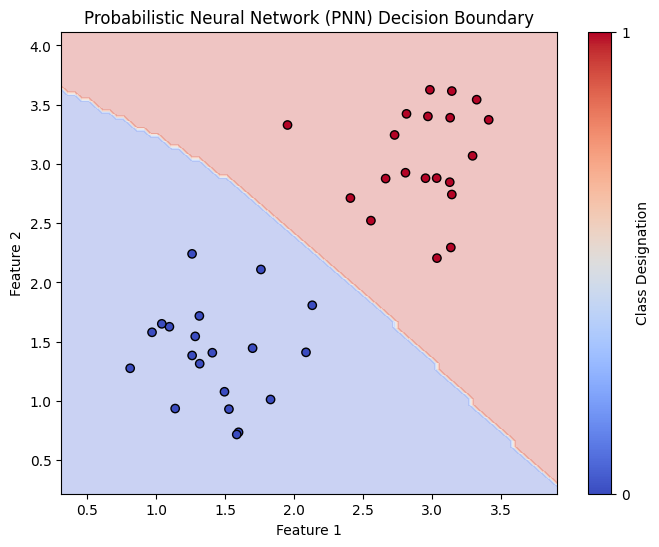

In [2]:

class ProbabilisticNeuralNetwork:
    def __init__(self, sigma=0.5):
        self.sigma = sigma

    def fit(self, X, y):
        self.X_train = X
        self.y_train = y
        self.classes = np.unique(y)

    def _gaussian_kernel(self, distance):
        return np.exp(-(distance ** 2) / (2 * self.sigma ** 2))

    def predict(self, X):
        predictions = []
        for sample in X:
            class_scores = {}
            for cls in self.classes:
                class_samples = self.X_train[
                    self.y_train == cls
                ]
                distances = np.linalg.norm(
                    class_samples - sample,
                    axis=1
                )
                probabilities = self._gaussian_kernel(
                    distances
                )
                class_scores[cls] = np.sum(
                    probabilities
                )
            predicted_class = max(
                class_scores,
                key=class_scores.get
            )
            predictions.append(predicted_class)
        return np.array(predictions)

if __name__ == "__main__":
    np.random.seed(42)
    X_train = np.vstack([
        np.random.normal(
            loc=[1.5, 1.5],
            scale=0.4,
            size=(20, 2)
        ),
        np.random.normal(
            loc=[3.0, 3.0],
            scale=0.4,
            size=(20, 2)
        )
    ])
    y_train = np.array(
        [0] * 20 + [1] * 20
    )
    pnn = ProbabilisticNeuralNetwork( sigma=0.5)
    pnn.fit(X_train, y_train)
    x_min = X_train[:, 0].min() - 0.5
    x_max = X_train[:, 0].max() + 0.5
    y_min = X_train[:, 1].min() - 0.5
    y_max = X_train[:, 1].max() + 0.5

    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, 0.05),
        np.arange(y_min, y_max, 0.05)
    )

    grid_points = np.c_[xx.ravel(),yy.ravel()]
    predictions = pnn.predict( grid_points )

    Z = predictions.reshape(xx.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, Z,alpha=0.3, cmap=plt.cm.coolwarm  )

    scatter = plt.scatter(
        X_train[:, 0], X_train[:, 1],
        c=y_train, cmap=plt.cm.coolwarm,
        edgecolors='black'
    )

    plt.title( "Probabilistic Neural Network (PNN) Decision Boundary")
    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")

    plt.colorbar(
        scatter,
        ticks=[0, 1],
        label="Class Designation"
    )

    plt.show()